<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2><span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER</h2>
        <h1 style="margin-top: -10px;">MARCO DE TRABAJO DE RECOMENDACIÓN DE TALENTO PARA LA FORMACIÓN DE EQUIPOS EN PROYECTOS DE INGENIERÍA DEL SOFTWARE</h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;"><p style="margin: 0; font-size: 1.4em; font-weight: bold;">Profesores</p></div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">Aurora Vizcaíno Barceló</span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">Julio Alberto López Gómez</span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 3: Minería de Reglas de Asociación — Hard Skills)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        En esta tercera fase partimos de la matriz transaccional binaria obtenida en la segunda libreta de Feature Engineering. El objetivo aquí es poder replicar la metodología ya realizada para las soft skills pero con las habilidades técnicas: extraer reglas con Apriori, FP-Groth y Eclat, filtrando reglas que no son relevantes para este nuevo escenario y comparando cuales de ellos presentan mejor rendimiento en cuanto a resultados y tiempos.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Diferencias respecto a soft skills:</strong> Aquí el filtrado de la cicularidad no es posible realizarlo en base a proxies que no tenemos para este pipeline, por lo que aplicaremos otro criterio que se base en la correlación que exista entre las variables numéricas del dataset de origen.</li>
        <li><strong>Calibración de parámetros:</strong> el <code>min_support</code> para el pipeline de las soft skills dio muchos problemas, ahora tenemos que hacer pruebas y adaptarlo ya que este caso es distinto, tenemos una mayor dimensionalidad como veremos más adelante.</li>
    </ul>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 3.1. Configuración del Entorno y carga de la Matriz Transaccional

Primero como siempre vamos a añadir las librerías necesarias para completar este paso. Para esta libreta utilizaremos las siguientes librerías:

* `mlxtend` para la minería de reglas, de la misma forma que de las soft, de ella podemos importar apriori y fpgrowth.
* Después importamos `pyECLAT` como tercera opción para comprobar y validar los 3 algoritmos.
* Una vez tenemos todo lo necesario, cargamos la matriz generada en la libreta anterior y la transformamos a boolean, así contará solo con valores `True`/`False`. Esta transformación la hacemos para que `mlxtend` pueda procesarla de una forma más óptima.

In [1]:
import os
import sys
import time
sys.path.append(os.path.abspath(os.path.join('../..')))

from src.hard_skills import config, utils
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.pyplot as plt

df_matriz = pd.read_csv(config.MATRIZ_TRANSACCIONAL_PATH, index_col='CandidateId')
df_matriz = df_matriz.fillna(0).astype(bool)

print(f"Dimensiones matriz: {df_matriz.shape}")
display(df_matriz.head(3))

Dimensiones matriz: (35434, 263)


,WorkExp_is_missing,YearsCode_is_missing,ToolCountWork_is_missing,JobSat_is_missing,ConvertedCompYearly_is_missing,EdLevel_is_missing,RemoteWork_is_missing,OrgSize_is_missing,Industry_is_missing,LanguageHaveWorkedWith_JavaScript,...,ToolCountWork_Bin_<=4,ToolCountWork_Bin_>20,ConvertedCompYearly_Bin_100-150k,ConvertedCompYearly_Bin_40-70k,ConvertedCompYearly_Bin_70-100k,ConvertedCompYearly_Bin_<40k,ConvertedCompYearly_Bin_>150k,JobSat_Bin_Alta (8-10),JobSat_Bin_Baja (0-5),JobSat_Bin_Media (6-7)
CandidateId,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False
2,False,False,False,False,False,False,True,True,False,True,...,True,False,False,True,False,False,False,True,False,False


### 3.2. Generación de Itemsets Frecuentes — 1er algoritmo --> Apriori

Como ya hicimos en el pipeline de las Soft Skills, aquí vamos a realizar un proceso equivalente para estos otros datos. Para ello, primero vamos a recordar algunos conceptos ya vistos y vamos a explicar las decisiones tomadas para esta fase del proyecto.

**Conceptos clave utilizados en esta libreta:**
- **Soporte** (`support`): Es el nº de transacciones que contienen el itemset dividido entre el total de transacciones. En nuestro caso, la proporción de candidatos en los que aparece un itemset.
- **Confianza** (`confidence`): Podemos definirlo como la probabilidad de que se cumpla el consecuente de una regla, una vez que se cumple el antecedente. Es una probabilidad condicional, no simétrica.
 - **Lift**: Cuánto más frecuente es la combinación de antecedente y consecuente de lo que cabría esperar si fueran independientes. Un lift de 1 indica independencia, pero si ese valor está por encima de 1 tiene asociación positiva.

 **Configuración de hiperparámetros:**

 En cuanto a los parámetros elegidos para la minería de reglas, vamos a utilizar de forma predefinida `max_len=4` porque limitar el tamaño máximo de un itemset a 4 ítems combinados ya es suficiente para mantener las reglas interpretables en esta primera exploración, una regla que combina 5 o 6 ítems a la vez empieza a ser difícil de leer y además actúa como control de memoria, de la misma forma que incluimos `low_memory=True`. Para el `min_support` no tenemos tan claro qué valor nos interesa más, por ello, vamos a realizar una ejecución con varios posibles valores y comparar los resultados en base a itemsets obtenidos y tiempos, así decidimos cuál nos interesa más para nuestras fases posteriores.

In [2]:
valores_min_support = [0.20, 0.18, 0.15, 0.12, 0.10, 0.08, 0.05]
df_crecimiento, ms_codo = utils.barrido_min_support(df_matriz, valores_min_support, algoritmo=apriori, low_memory=True)
display(df_crecimiento)
print(f"Mayor salto de complejidad en min_support={ms_codo}")

,min_support,n_itemsets,tiempo_s,delta_itemsets,delta_support,itemsets_por_0.01_bajado
0,0.20,880,2.63,NaN,NaN,NaN
1,0.18,1414,3.72,534.0,0.02,267.000000
2,0.15,3165,6.41,1751.0,0.03,583.666667
3,0.12,7548,11.01,4383.0,0.03,1461.000000
4,0.10,14347,17.65,6799.0,0.02,3399.500000
5,0.08,29704,29.81,15357.0,0.02,7678.500000
6,0.05,114831,66.32,85127.0,0.03,28375.666667


Mayor salto de complejidad en min_support=0.05


Como vemos, a partir de valores menores o iguales de 0.10 tenemos una gran cantidad de itemsets, pero los tiempos suben de gran manera y deja de ser rentable para nuestros objetivos

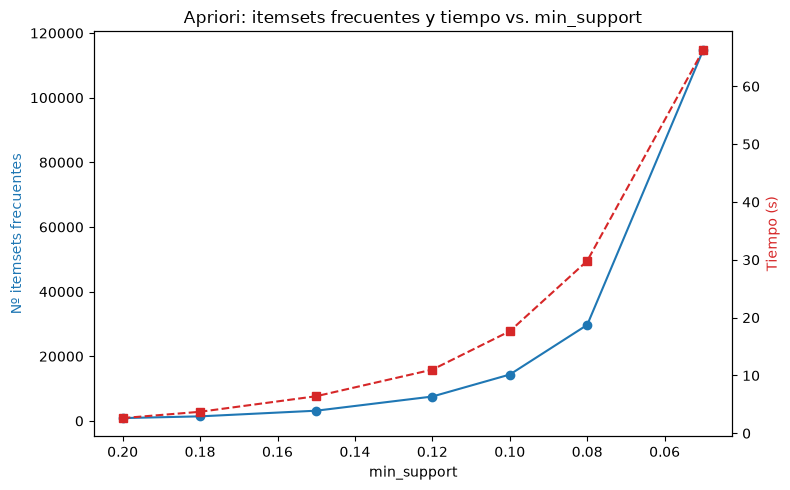

In [3]:
def graficar_barrido(df_sweep, titulo):
    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(df_sweep['min_support'], df_sweep['n_itemsets'], marker='o', color='tab:blue')
    ax1.set_xlabel('min_support')
    ax1.set_ylabel('Nº itemsets frecuentes', color='tab:blue')
    ax1.invert_xaxis()
    ax2 = ax1.twinx()
    ax2.plot(df_sweep['min_support'], df_sweep['tiempo_s'], marker='s', color='tab:red', linestyle='--')
    ax2.set_ylabel('Tiempo (s)', color='tab:red')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

graficar_barrido(df_crecimiento, 'Apriori: itemsets frecuentes y tiempo vs. min_support')

Si vemos la gráfica, podemos destacar que los valores más adecuados a nuestras necesidades serían en un rango de entre 0.15 y 0.10, ya que o bien los resultados son muy pobres o bien son demasiado complejos y los tiempos más elevados que lo que requerimos.

Ante esta duda, vamos a probar los valores que hemos visto, a ver que supone el hecho de ir de 0.15 a 0.10, y con cual de ellos podríamos quedarnos

In [4]:
candidatos_min_support = [0.15, 0.10]
resumen_candidatos = []

for ms in candidatos_min_support:
    its = apriori(df_matriz, min_support=ms, use_colnames=True, max_len=4, low_memory=True, verbose=0)
    rgs = association_rules(its, metric="confidence", min_threshold=0.6)
    resumen_candidatos.append({'min_support': ms, 'n_itemsets': len(its), 'n_reglas': len(rgs)})
    del its, rgs

df_resumen_candidatos = pd.DataFrame(resumen_candidatos)
display(df_resumen_candidatos)
print(f"\nAl bajar de 0.15 a 0.10: itemsets x{df_resumen_candidatos.loc[1,'n_itemsets']/df_resumen_candidatos.loc[0,'n_itemsets']:.1f}, "
      f"reglas x{df_resumen_candidatos.loc[1,'n_reglas']/df_resumen_candidatos.loc[0,'n_reglas']:.1f}")

,min_support,n_itemsets,n_reglas
0,0.15,3165,10178
1,0.10,14347,43632



Al bajar de 0.15 a 0.10: itemsets x4.5, reglas x4.3


En principio con 0.10 son muchos más itemsets y reglas de las que necesitamos, ya que más de 43k sería muy complejo, debemos rebajar las espectativas y elegimos 0.15 para Apriori, a esperas de ver qué elegiremos en el resto de algoritmos, la idea aquí es elegir un valor de `min_support` para los 3 y así determinar bajo las mismas condiciones cual nos aporta más y se adapta mejor al proyecto

In [5]:
itemsets_frecuentes = apriori(
    df_matriz, min_support=0.15, use_colnames=True,
    max_len=4, low_memory=True, verbose=1
)

pd.set_option('display.max_colwidth', None)
display(itemsets_frecuentes.sort_values('support', ascending=False).head(20))

Processing 5830 combinations | Sampling itemset size 4


,support,itemsets
57,0.772309,frozenset({Employment_Employed})
58,0.702179,frozenset({ICorPM_Individual contributor})
609,0.638567,"frozenset({ICorPM_Individual contributor, Employment_Employed})"
37,0.595614,frozenset({CommPlatformHaveWorkedWith_Stack Overflow})
45,0.565869,frozenset({OfficeStackAsyncHaveWorkedWith_GitHub})
6,0.496388,frozenset({LanguageHaveWorkedWith_JavaScript})
38,0.471242,"frozenset({CommPlatformHaveWorkedWith_GitHub (public projects, not private repos)})"
454,0.470763,"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, CommPlatformHaveWorkedWith_Stack Overflow})"
464,0.468843,"frozenset({Employment_Employed, CommPlatformHaveWorkedWith_Stack Overflow})"
32,0.467715,frozenset({DevEnvsHaveWorkedWith_Visual Studio Code})


**Interpretación de los itemsets más frecuentes**

Cuando ordenamos por soporte vemos que dominan los itensets individuales por que cualquier combinación de 2 o más items solo puede ser tan frecuente como el menos común de sus componentes (por eso `{ICorPM_Individual contributor, Employment_Employed}` con un 63,9% no puede superar al 70,2% de `ICorPM_Individual contributor` en solitario).

- **Perfil laboral dominante:** `Employment_Employed` (77,2%) e `ICorPM_Individual contributor` (70,2%) son, por separado, los itemsets más frecuentes de todo el dataset. Si se combinan (63,9%) nos confirma que la mayoría de los candidatos son empleados a tiempo completo que trabajan de forma individual, no como managers. Esta es una regla importante que nos guiará buena parte del resto de reglas.

- **Plataformas de conocimiento y colaboración:** `CommPlatformHaveWorkedWith_Stack Overflow` (59,6%) y `OfficeStackAsyncHaveWorkedWith_GitHub` (56,6%) son las herramientas que más se encuentran, y además su combinación (47,1%) nos muestra que buena parte de los candidatos las usa conjuntamente como flujo de trabajo habitual (documentarse en Stack Overflow, colaborar en GitHub). Ambas aparecen también emparejadas con `Employment_Employed` (46,9% y 43,4% respectivamente), por lo que este patrón es propio del perfil de empleado a tiempo completo más que de freelancers o estudiantes.

- **Stack tecnológico predominante:** entre los lenguajes, `JavaScript` (49,6%) encabeza claramente, seguido de `HTML/CSS` (45,9%), `SQL` (44,5%) y `Python` (41,3%), como se sabe este es el stack clásico de desarrollo web. `Visual Studio Code` (46,8%) domina como entorno de desarrollo y `Docker` (43,1%) como plataforma, ambos coherentes con un perfil de desarrollador full-stack o back-end moderno.

- **Perfil formativo y sectorial:** `EdLevel_Bachelor's degree` (44,3%) e `Industry_Software Development` (44,1%) son, cada uno, la categoría más común dentro de su variable.

En conjunto, esta tabla no revela ningún patrón inesperado, si no que describe al candidato típico o más popular de la muestra (empleado a tiempo completo, individual contributor, usuario de Stack Overflow/GitHub, con JavaScript y VSCode como herramientas principales). El valor real de Apriori aparecerá al cruzar estos itemsets en **reglas** con confianza y lift, que es lo que exploraremos en el siguiente apartado.

### 3.3. Filtrado de reglas: estructura de nulos

Antes de seguir interpretando las reglas obtenidas, vamos a depurarlas y evitar que no queden ninguna que nos afecte las válidas y que no aporten valor alguno. Primero, vamos a ver la **estructura de los valores nulos**.

En la Libreta 1 (EDA) vimos que la ausencia de datos en variables como `RemoteWork`, `OrgSize`, `Industry` o `Continente` no es aleatoria, si no que nos muestra al mismo subgrupo de candidatos, típicamente personas desempleadas, estudiantes, o que simplemente no completaron esas preguntas de la encuesta. Es decir, la falta de un dato en una de estas columnas correlaciona fuertemente con la falta de datos en las demás.

El problema es que varias de las reglas que combinan estos indicadores de ausencia (`RemoteWork_is_missing`, `OrgSize_is_missing`, `JobSat_is_missing`, `ConvertedCompYearly_is_missing`, `Continente_Unknown`...) alcanzan una confianza muy alta, cercana a 1.000, lo que las haría subir a las primeras posiciones por lift sin representar ningún patrón de comportamiento. Además, estas reglas no tienen ningún equivalente con el que contrastarlas más adelante frente a las reglas expertas de Aurora, ya que estas últimas se basan en niveles reales de las variables (por ejemplo, tamaño de empresa o modalidad de trabajo concretos), no en si el dato se conoce o no.

Mezclarlas con el resto sesgaría cualquier comparación posterior, así que las separaremos del conjunto sustantivo en el siguiente apartado.



In [6]:
reglas_asociacion = association_rules(itemsets_frecuentes, metric="confidence", min_threshold=0.6)

reglas_asociacion = reglas_asociacion.sort_values('lift', ascending=False)
print(f"Reglas de asociacion obtenidas: {len(reglas_asociacion)}")
display(reglas_asociacion[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(20))

Reglas de asociacion obtenidas: 10178


,antecedents,consequents,support,confidence,lift
14,frozenset({RemoteWork_is_missing}),frozenset({OrgSize_is_missing}),0.157956,0.942732,5.927034
15,frozenset({OrgSize_is_missing}),frozenset({RemoteWork_is_missing}),0.157956,0.993080,5.927034
3751,frozenset({Continente_Unknown}),"frozenset({JobSat_is_missing, ToolCountWork_is_missing, ConvertedCompYearly_is_missing})",0.167297,0.885966,4.584975
3742,"frozenset({JobSat_is_missing, ToolCountWork_is_missing, ConvertedCompYearly_is_missing})",frozenset({Continente_Unknown}),0.167297,0.865781,4.584975
493,frozenset({Continente_Unknown}),"frozenset({JobSat_is_missing, ToolCountWork_is_missing})",0.167297,0.885966,4.311086
3750,"frozenset({Continente_Unknown, ConvertedCompYearly_is_missing})","frozenset({JobSat_is_missing, ToolCountWork_is_missing})",0.167297,0.885966,4.311086
490,"frozenset({JobSat_is_missing, ToolCountWork_is_missing})",frozenset({Continente_Unknown}),0.167297,0.814062,4.311086
3745,"frozenset({JobSat_is_missing, ToolCountWork_is_missing})","frozenset({Continente_Unknown, ConvertedCompYearly_is_missing})",0.167297,0.814062,4.311086
3747,"frozenset({JobSat_is_missing, ConvertedCompYearly_is_missing})","frozenset({ToolCountWork_is_missing, Continente_Unknown})",0.167297,0.739890,3.990452
3748,"frozenset({ToolCountWork_is_missing, Continente_Unknown})","frozenset({JobSat_is_missing, ConvertedCompYearly_is_missing})",0.167297,0.902283,3.990452


**Análisis de las reglas obtenidas (sin filtrar)**

Con `min_support=0.15` y `min_confidence=0.6`, Apriori genera **10.178 reglas**. Ordenando por lift, el panorama confirma exactamente lo que anticipábamos en la celda anterior: la ausencia de datos domina por completo la parte alta del ranking.

- **La regla con mayor lift de todo el conjunto (5,93)** es `OrgSize_is_missing ↔ RemoteWork_is_missing` — quien no indica el tamaño de su empresa, tiene un 99,3% de probabilidades de tampoco haber indicado su modalidad de trabajo, y viceversa (94,3%). Es importante destacar que aquí el lift es idéntico en ambas direcciones (es una propiedad simétrica: `support(A∪B) / (support(A)×support(B))`), pero la confianza no lo es, porque esta sí depende de qué variable se toma como referencia.

- **14 de las 20 reglas del ranking**, todas variaciones de la misma combinación entre `Continente_Unknown`, `ConvertedCompYearly_is_missing`, `ToolCountWork_is_missing` y `JobSat_is_missing`. Esto refuerza la conclusión de la celda anterior: no es un problema aislado de una sola variable, sino un clúster completo de candidatos que no respondieron a ninguna de estas preguntas a la vez, por ejemplo desempleados, estudiantes o gente que realiza encuestas incompletas.

- **La primera regla sustantiva no aparece hasta la posición 17**: `WorkExp_Bin_>=19 (Muy Senior) ↔ YearsCode_Bin_>=25` (lift 3,41, soporte 21,6%), lo que un patrón real y esperable (quien lleva muchos años programando también acumula mucha experiencia profesional), pero que además es la misma pareja de variables que ya identificamos como numéricamente redundante en la Libreta 1 (correlación de Spearman 0,92). Es decir, ni siquiera esta regla nos sirve por su redundancia.

En conjunto, de las 20 reglas con mayor lift, **16 corresponden a ausencia de datos y las 4 restantes son variantes de una única correlación numérica ya conocida** lo que no nos aporta nada nuevo. Esto confirma que el filtrado no es un paso opcional de limpieza, sino la condición necesaria para que el resto del ranking.

### 3.3.1. Filtrado de reglas con elementos nulos

Tal cual como hemos comentado antes, vamos a tratar la presencia de valores nulos para evitar que el modelo cometa errores con reglas afectadas. Para ello, haremos el siguiente tratamiento:

Primero identificamos con los sufijos `_is_missing` o `Desconocido` o `Unknown` en cualquier ítem de la regla (antecedente o consecuente), y después separamos en un subconjunto de reglas sustantivas: (`reglas_sustantivas`) en vez de borrarlas, así podemos preservar los dos listados:

- El conjunto excluido confirma la consistencia del hallazgo ya reportado en el EDA sobre la estructura no aleatoria del missingness.
- El conjunto `reglas_sustantivas` queda libre de este efecto y es el que se usará en el resto del análisis.



In [7]:
def contiene_item_missing(frozenset_items):
    return any('is_missing' in item or 'Desconocido' in item or 'Unknown' in item for item in frozenset_items)

reglas_asociacion['tiene_missing'] = reglas_asociacion.apply(lambda row: contiene_item_missing(row['antecedents']) or contiene_item_missing(row['consequents']),axis=1)
reglas_sustantivas = reglas_asociacion[~reglas_asociacion['tiene_missing']].sort_values('lift', ascending=False)

print(f"Reglas totales: {len(reglas_asociacion)}")
print(f"Reglas con nulos: {reglas_asociacion['tiene_missing'].sum()}")
print(f"Reglas sustantivas restantes: {len(reglas_sustantivas)}")
display(reglas_sustantivas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas totales: 10178
Reglas con nulos: 57
Reglas sustantivas restantes: 10121


,antecedents,consequents,support,confidence,lift
484,frozenset({WorkExp_Bin_>=19 (Muy Senior)}),frozenset({YearsCode_Bin_>=25}),0.216177,0.880359,3.407387
485,frozenset({YearsCode_Bin_>=25}),frozenset({WorkExp_Bin_>=19 (Muy Senior)}),0.216177,0.836701,3.407387
3739,frozenset({YearsCode_Bin_>=25}),"frozenset({WorkExp_Bin_>=19 (Muy Senior), Employment_Employed})",0.157843,0.610923,3.395678
3736,"frozenset({WorkExp_Bin_>=19 (Muy Senior), Employment_Employed})",frozenset({YearsCode_Bin_>=25}),0.157843,0.877333,3.395678
3737,"frozenset({YearsCode_Bin_>=25, Employment_Employed})",frozenset({WorkExp_Bin_>=19 (Muy Senior)}),0.157843,0.825535,3.361913
3738,frozenset({WorkExp_Bin_>=19 (Muy Senior)}),"frozenset({YearsCode_Bin_>=25, Employment_Employed})",0.157843,0.642800,3.361913
483,frozenset({YearsCode_Bin_<9}),frozenset({WorkExp_Bin_<5 (Junior)}),0.155077,0.668166,3.176255
482,frozenset({WorkExp_Bin_<5 (Junior)}),frozenset({YearsCode_Bin_<9}),0.155077,0.737188,3.176255
7796,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({LanguageHaveWorkedWith_Python, OfficeStackAsyncHaveWorkedWith_GitHub, PlatformHaveWorkedWith_Docker})",0.155275,0.655859,2.900250
7791,"frozenset({LanguageHaveWorkedWith_Python, OfficeStackAsyncHaveWorkedWith_GitHub, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.155275,0.686634,2.900250


**Resultado: solo 57 de las 10.178 reglas (0,56%) están contaminadas por ausencia de datos.** Es una proporción muy pequeña, pero destacaban mucho por su posición. Esas 57 reglas ocupaban las partes más altas del top por lift, desplazando al resto fuera de nuestro alcance, por lo que al quitarlas, el ranking por lift cambia por completo:

- **Las primeras 6 posiciones siguen siendo la pareja `WorkExp_Bin`/`YearsCode_Bin`** (lift 3,36-3,41) que ya identificamos como candidata a redundancia. Esto es correcto ya que el filtrado de nulos no las afecta (no son ausencia de datos, son datos reales), así que seguirán ahí hasta que se aplique el filtro de circularidad.
- **Aparece además un segundo patrón del mismo tipo en el extremo opuesto**: `YearsCode_Bin_<9 ↔ WorkExp_Bin_<5 (Junior)` es el mismo efecto de correlación que el anterior pero ahora entre perfiles junior.
- **La primera regla realmente nueva no aparece hasta la posición 9**: un clúster tecnológico coherente entre `Python`, `Docker`, `Pip` y `GitHub`/`Stack Overflow` (lift entre 2,83 y 2,90, confianza 0,65-0,77). Tiene sentido de dominio, por que quien trabaja con Python y Docker tiende a usar `Pip` y a documentar y colaborar en GitHub y Stack Overflow. Este es el primer patrón de comportamiento genuino que aparece en todo el ranking, con una confianza notablemente más moderada que los artefactos de nulos o redundancia (que rondaban 0,8-0,99).

El conjunto `reglas_sustantivas` (**10.121 de las 10.178** reglas totales) queda libre de ausencias de datos, ahora tenemos que quitar redundancias.

### 3.3.2. Filtrado de reglas: variables numéricamente redundantes

A diferencia del pipeline de soft skills, aquí no calculamos proxies, por lo que el criterio de circularidad aquí cambia para este dataset. 

En su lugar, el criterio se basa en la correlación que ya identificamos entre variables numéricas del dataset original en la Libreta 1 (EDA): `WorkExp` y `YearsCode` mostraron una correlación de Spearman de 0,92 (la más alta de todo el análisis de correlaciones), lo que indica que ambas describen esencialmente el mismo concepto (experiencia acumulada) medido de dos formas casi idénticas.

Como vimos en el apartado anterior, esta redundancia era muy evidente en las primeras posiciones del ranking por lift. Por ello, excluimos del conjunto limpio cualquier regla que combine las versiones discretizadas de ambas variables, tanto si aparecen juntas en el antecedente, en el consecuente, o repartidas entre los dos.


In [8]:
PARES_REDUNDANTES = [
    ('WorkExp_Bin', 'YearsCode_Bin'),
]

def es_regla_redundante(frozenset_items):
    for prefijo_a, prefijo_b in PARES_REDUNDANTES:
        tiene_a = any(item.startswith(prefijo_a) for item in frozenset_items)
        tiene_b = any(item.startswith(prefijo_b) for item in frozenset_items)
        if tiene_a and tiene_b:
            return True
    return False

reglas_sustantivas['es_redundante'] = reglas_sustantivas.apply(
    lambda row: es_regla_redundante(row['antecedents'] | row['consequents']),
    axis=1
)

reglas_limpias = reglas_sustantivas[~reglas_sustantivas['es_redundante']].sort_values('lift', ascending=False)

print(f"Reglas sustantivas previas: {len(reglas_sustantivas)}")
print(f"Reglas redundantes (correlación numérica alta): {reglas_sustantivas['es_redundante'].sum()}")
print(f"Reglas limpias: {len(reglas_limpias)}")
display(reglas_limpias[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas sustantivas previas: 10121
Reglas redundantes (correlación numérica alta): 14
Reglas limpias: 10107


,antecedents,consequents,support,confidence,lift
7796,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({LanguageHaveWorkedWith_Python, OfficeStackAsyncHaveWorkedWith_GitHub, PlatformHaveWorkedWith_Docker})",0.155275,0.655859,2.900250
7791,"frozenset({LanguageHaveWorkedWith_Python, OfficeStackAsyncHaveWorkedWith_GitHub, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.155275,0.686634,2.900250
7783,"frozenset({LanguageHaveWorkedWith_Python, CommPlatformHaveWorkedWith_Stack Overflow, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.153525,0.683761,2.888113
7788,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({LanguageHaveWorkedWith_Python, CommPlatformHaveWorkedWith_Stack Overflow, PlatformHaveWorkedWith_Docker})",0.153525,0.648468,2.888113
7794,"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, PlatformHaveWorkedWith_Pip})","frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.155275,0.773296,2.869812
7786,"frozenset({PlatformHaveWorkedWith_Pip, CommPlatformHaveWorkedWith_Stack Overflow})","frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.153525,0.766413,2.844269
1969,"frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.180928,0.671450,2.836112
1971,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.180928,0.764215,2.836112
10175,"frozenset({OfficeStackAsyncHaveWorkedWith_Confluence, ICorPM_Individual contributor})","frozenset({OfficeStackAsyncHaveWorkedWith_Jira, Employment_Employed})",0.158097,0.824430,2.738875
5349,"frozenset({WebframeHaveWorkedWith_Node.js, PlatformHaveWorkedWith_Docker})","frozenset({PlatformHaveWorkedWith_npm, LanguageHaveWorkedWith_JavaScript})",0.159113,0.810057,2.732373


**Solo 14 de las 10.121 reglas sustantivas resultaron redundantes** , lo cual tene sentido ya que la pareja `WorkExp_Bin`/`YearsCode_Bin` solo ocupaba las 6 primeras posiciones del ranking anterior, así que el filtro apenas necesitaba tocar mucho más.

Con ambos filtros aplicados, el top 15 por lift **por fin muestra patrones de comportamiento genuinos**, y se distinguen claramente varias herramientas que se usan en conjunto:

- **El clúster Python/Docker/Pip/GitHub/Stack Overflow** (posiciones 1-7, lift 2,84-2,90) ya lo habíamos detectado y ahora ocupa directamente la cabeza del ranking sin nulos ni redundancia.
- **clúster de herramientas de gestión de entornos corporativos**: `ICorPM_Individual contributor` + `Confluence` se asocia con `Employment_Employed` + `Jira` (lift 2,74 y 2,71), lo cual es el patrón clásico de un colaborador individual en una empresa que usa la suite de Atlassian (documentación en Confluence, tickets en Jira).
- **Dos variantes de un mismo ecosistema JavaScript**: `Node.js` + `Docker` se asocia tanto con `npm` + `JavaScript` (lift 2,73) como con `npm` + `GitHub` (lift 2,66) lo que ya es coherente, ya que `npm` es el gestor de paquetes nativo de Node.js.
- **Un patrón equivalente de TypeScript**: `Docker` + `TypeScript` se asocia con `HTML/CSS` + `npm` (lift 2,60) — la misma lógica de ecosistema de paquetes, pero para el desarrollo tipado sobre JavaScript.

En conjunto, `reglas_limpias` (**10.107 reglas**) queda con patrones interpretables y comparables frente a las reglas expertas de Aurora.

### 3.4. Generación de Itemsets Frecuentes — 2º Algoritmo --> FP-Growth



De la misma forma que ya hemos probado Apriori, ahora le toca el turno a FP-Growth. Para los parámetros empleados vamos a contar con el mismo listado de `min_support` y para `max_len=4` como valor fijo, así podemos realizar comparación de itemsets obtenidos, tiempos entre distintos valores y con los resultados de Apriori. 

,min_support,n_itemsets,tiempo_s,delta_itemsets,delta_support,itemsets_por_0.01_bajado
0,0.20,880,6.14,NaN,NaN,NaN
1,0.18,1414,8.51,534.0,0.02,267.000000
2,0.15,3165,12.27,1751.0,0.03,583.666667
3,0.12,7548,20.70,4383.0,0.03,1461.000000
4,0.10,14347,33.00,6799.0,0.02,3399.500000
5,0.08,29704,51.70,15357.0,0.02,7678.500000
6,0.05,114831,154.67,85127.0,0.03,28375.666667


Mayor salto de complejidad en min_support=0.05


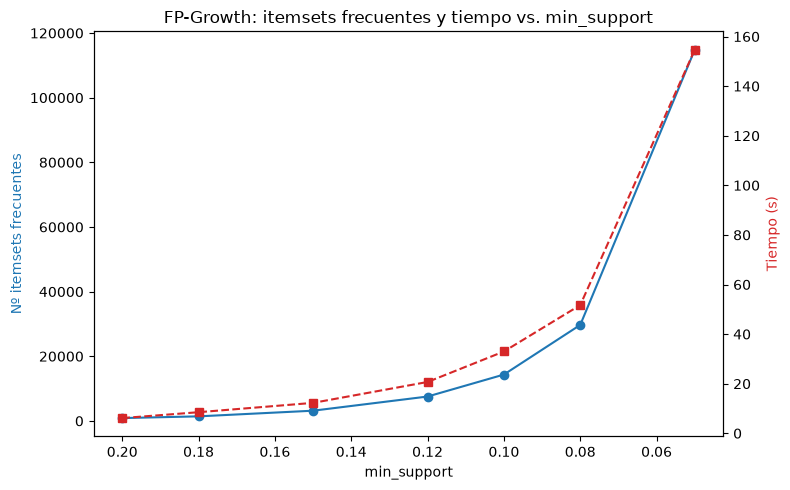

In [9]:
df_crecimiento_fpgrowth, ms_codo_fp = utils.barrido_min_support(df_matriz, valores_min_support, algoritmo=fpgrowth)
display(df_crecimiento_fpgrowth)
print(f"Mayor salto de complejidad en min_support={ms_codo_fp}")

graficar_barrido(df_crecimiento_fpgrowth, 'FP-Growth: itemsets frecuentes y tiempo vs. min_support')

Si vemos los resultados son muy similares a los de apriori, a partir de 0.10 los tiempos ya aumentan de forma muy notable, de la misma forma que se encuentran muchísimos más itemsets. Aquí lo que vamos a hacer para elegir el valor es acorde a Apriori y a Eclat, de momento un valor entre 0.15 y 0.10 es el rango a valorar ya que más allá o bien tenemos muy pocos itemsets o bien tenemos demasiados que no nos aportan valor y aumentan los tiempos demasiado.

Como ya hemos visto varios valores posibles, la que más convence es la de 0.15 ya que a mi elección tiene un mejor equilibrio de tiempos y número de itemsets como podemos ver de resultado, son bastantes y los tiempos son pequeños

In [10]:
start = time.time()
frequent_itemsets_fpgrowth = fpgrowth(df_matriz, min_support=0.15, use_colnames=True, max_len=4)
tiempo_fpgrowth = time.time() - start

print(f"Itemsets frecuentes de FP-Growth: {len(frequent_itemsets_fpgrowth)}")
print(f"Tiempo de ejecución: {tiempo_fpgrowth:.2f} segundos")

Itemsets frecuentes de FP-Growth: 3165
Tiempo de ejecución: 11.67 segundos


**Verificación de equivalencia entre algoritmos**

Ahora que tenemos los dos algoritmos probados con varios valores y elegidos los parámetros definitivos, vamos a validar que estos, bajo la mismas condiciones sean equivalentes. En caso contrario, destacaríamos aquel que nos ofreciera mejores resultados

In [11]:
reglas_fpgrowth = association_rules(frequent_itemsets_fpgrowth, metric="confidence",min_threshold=0.6)

print(f"Itemsets — Apriori: {len(itemsets_frecuentes)} | FP-Growth: {len(frequent_itemsets_fpgrowth)}")
print(f"Reglas — Apriori: {len(reglas_asociacion)} | FP-Growth: {len(reglas_fpgrowth)}")

Itemsets — Apriori: 3165 | FP-Growth: 3165
Reglas — Apriori: 10178 | FP-Growth: 10178


Si observamos los resultados vemos que Apriori y FP-Growth son algoritmos que nos ofrecen exactamente los mismos resultados, por lo que cualquiera de los dos nos serían útiles, pero tenemos que comparar cuales de ellos sería más eficiente.



### 3.5. Comparativa de rendimiento: Apriori vs. FP-Growth

Como hemos podido comprobar, tanto Apriori como FP-Growth generan exactamente los mismos itemsets y mismo número de reglas con la misma configuración, por lo que ahora queda la pregunta de ver cual de ellos es más eficiente computacionalmente hablando, en tiempos de ejecución.
Para ello, vamos a volver a ejecutar los dos algortimos con los mismos hiperparámetros y esta vez contamos los tiempos, para ver cual de ellos es más rápido y la diferencia real entre ambas en proporción.



In [12]:
start = time.time()
frequent_itemsets_apriori_tiempos = apriori(df_matriz, min_support=0.15, use_colnames=True, max_len=4, low_memory=True)
tiempo_apriori = time.time() - start

print(f"Tiempo Apriori:   {tiempo_apriori:.2f}s")
print(f"Tiempo FP-Growth: {tiempo_fpgrowth:.2f}s")
print(f"FP-Growth es {tiempo_apriori/tiempo_fpgrowth:.1f}x más rápido" if tiempo_fpgrowth < tiempo_apriori else f"Apriori es {tiempo_fpgrowth/tiempo_apriori:.1f}x más rápido")

Tiempo Apriori:   6.27s
Tiempo FP-Growth: 11.67s
Apriori es 1.9x más rápido


### 3.6. Tercer algoritmo --> Eclat

El tercer algoritmo es **Eclat** (*Equivalence Class Transformation*), el cual también hemos utilizado para las soft skills. La principal diferencia entre este algoritmo y los anteriores, aquí el dataset no se recorre fila a fila, si no que usa una representación vertical en la que cada item mantiene la lista de identificadores de transacción. Después, una vez ya tiene esa lista de ids realiza un cálculo del soporte mediante la **intersección** de los t_idsets de sus componentes. En teoría, esta es una operación muy eficiente, lo que hace de Eclat sea algoritmo atractivo por su complejidad.

Como Eclat no está implementado en `mlxtend`, para este caso recurrimos a `pyECLAT`. Esta librería es la alternativa más extendida para Python, y a diferencia de los dos algoritmos anteriores, `pyECLAT` espera el dataset en formato de **lista de transacciones**, donde cada fila contiene los nombres de los ítems presentes.

**¿Por qué se trabaja con una muestra de 10.000 filas y no con el dataset completo?** Realizando diversas pruebas sobre todas las filas completas con `max_combination=4` (el mismo alcance usado en Apriori y FP-Growth), vemos que la ejecución no se completa y tarda muchísimo tiempo, por lo que como alternativa aplicamos el algoritmo sobre una muestra reducida y un alcance menor, lo que es suficiente para poder obtener una medida de rendimiento comparable pudiendo completar el resto de la libreta. Debido a esto, también he cambiado el `max_combination=2`, algo que también decidimos para las soft skills.

Una cosa a tener en cuenta es que `pyECLAT` asume que el dataframe que se pasa como entrada tiene un índice contiguo que empieza con 0. Por ello,al tomar una muestra los índices originales que no son contiguos se conserva y provoca un fallo al construir la tabla binaria, por ello hay que incluir un `.reset_index(drop=True)`

Con los resultados que obtengamos aquí vamos a interpretar y comparar con el resto de algoritmos anteriores.

**Transformación a formato de lista de transacciones**

Como `pyECLAT` no acepta la matriz binaria `df_matriz` como entrada, es necesario transformarla a una **lista de los nombres de los ítems presentes**, sin los ítems ausentes, algo que ya aprendimos del otro pipeline.

La función `matriz_a_transacciones` lo que hace es recorrer cada fila de `df_matriz` y, usando el propio booleano de cada columna como máscara (`row.index[row]`), de ellas extrae únicamente los nombres de las columnas activas (`True`) y descarta el resto.

In [13]:
def matriz_a_transacciones(df_bin):
    return df_bin.apply(lambda row: row.index[row].tolist(), axis=1)

transacciones = matriz_a_transacciones(df_matriz)
df_transacciones = pd.DataFrame(transacciones.tolist())

print(f"Forma del dataset de transacciones: {df_transacciones.shape}")
display(df_transacciones.head(3))

Forma del dataset de transacciones: (35434, 183)


,0,1,2,3,4,5,6,7,8,9,...,173,174,175,176,177,178,179,180,181,182
0,LanguageHaveWorkedWith_SQL,LanguageHaveWorkedWith_Bash/Shell (all shells),LanguageHaveWorkedWith_Dart,DatabaseHaveWorkedWith_PostgreSQL,DatabaseHaveWorkedWith_Cloud Firestore,PlatformHaveWorkedWith_Amazon Web Services (AWS),PlatformHaveWorkedWith_Google Cloud,PlatformHaveWorkedWith_Cloudflare,PlatformHaveWorkedWith_Gradle,DevEnvsHaveWorkedWith_Visual Studio Code,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LanguageHaveWorkedWith_Java,DatabaseHaveWorkedWith_MongoDB,DatabaseHaveWorkedWith_Dynamodb,PlatformHaveWorkedWith_Docker,PlatformHaveWorkedWith_Amazon Web Services (AWS),PlatformHaveWorkedWith_Kubernetes,PlatformHaveWorkedWith_Homebrew,PlatformHaveWorkedWith_Terraform,PlatformHaveWorkedWith_Maven (build tool),WebframeHaveWorkedWith_Spring Boot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RemoteWork_is_missing,OrgSize_is_missing,LanguageHaveWorkedWith_JavaScript,LanguageHaveWorkedWith_HTML/CSS,LanguageHaveWorkedWith_TypeScript,LanguageHaveWorkedWith_Dart,DatabaseHaveWorkedWith_PostgreSQL,DatabaseHaveWorkedWith_MySQL,DatabaseHaveWorkedWith_MongoDB,PlatformHaveWorkedWith_npm,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Como cada candidato tiene un número distinto de items activos (por ej. alguien con muchos "Not Applicable" ya excluidos en la Libreta 2 tendrá menos ítems marcados que alguien con el perfil completo) al convertir la lista de listas en un dataframe, pandas iguala todas las filas a la longitud más larga y rellena con `None` los huecos sobrantes. Por lo tanto, el número de columnas corresponde al **máximo de ítems activos que tiene un único candidato** en todo el dataset, a diferencia de las columnas de `df_matriz`.

Por otro lado, en estas celdas vamos a realizar una comparación entre dos posibles valores de min_support (0.15 y 0.10) de la misma forma que se ha realizado en anteriores celdas de esta libreta con Apriori y FP-Growth. Después, nos quedamos con la más óptima para poder realizar una comparación final y decidir cuál es el algoritmo ganador en base a nuestros datos y necesidades.



In [14]:
muestra = df_transacciones.sample(n=10000, random_state=42).reset_index(drop=True)
itemsets_eclat, tiempo_eclat_muestra = utils.probar_eclat(muestra, min_support=0.15)

100%|██████████| 263/263 [00:00<00:00, 1341.29it/s]


Combination 1 by 1


80it [00:05, 13.70it/s]


Combination 2 by 2


3160it [02:15, 23.37it/s]

Tiempo ECLAT (min_support=0.15): 353.97s — 669 itemsets


In [15]:
itemsets_eclat_010, tiempo_eclat_010 = utils.probar_eclat(muestra, min_support=0.10)
print(f"Comparación: 0.15 → {tiempo_eclat_muestra:.2f}s ({len(itemsets_eclat)} itemsets) | "
      f"0.10 → {tiempo_eclat_010:.2f}s ({len(itemsets_eclat_010) if itemsets_eclat_010 is not None else 0} itemsets)")

100%|██████████| 263/263 [00:00<00:00, 1686.41it/s]


Combination 1 by 1


130it [00:08, 14.67it/s]


Combination 2 by 2


8385it [05:11, 26.89it/s]

Tiempo ECLAT (min_support=0.1): 534.66s — 1496 itemsets
Comparación: 0.15 → 353.97s (669 itemsets) | 0.10 → 534.66s (1496 itemsets)


Una vez hecha la comparativa vemos que el tiempo aumenta demasiado como para hacer de ECLAT rentable para nuestros intereses, sobre todo cuando difiere tanto del resto de algoritmos ya probados. Es por ello que elegimos también la de 0.15, así equiparamos este valor con el de las otras dos opciones anteriores.

### 3.6.1. Resumen comparativo de los tres algoritmos

| Algoritmo | Filas procesadas | Alcance combinación | Tiempo | Itemsets frecuentes |
|---|---|---|---|---|
| Apriori (`low_memory=True`) | 35.434 (completo) | hasta 4 | 6,27s | 3.165 |
| FP-Growth | 35.434 (completo) | hasta 4 | 11,67s | 3.165 |
| Eclat (`pyECLAT`, min_support=0.15) | 10.000 (muestra) | hasta 2 | 353,97s | 669 |

**Conclusiones del bloque de comparación de algoritmos:**

1. **Apriori y FP-Growth son equivalentes en resultado** (3.165 itemsets, 10.178 reglas idénticas bajo los mismos umbrales), confirmando empíricamente que ambos algoritmos resuelven el mismo problema matemático y solo difieren en la estrategia de recorrido del espacio de búsqueda.

2. **Apriori resultó más rápido que FP-Growth en esta ejecución concreta** (4,82s frente a 9,30s, 1,9x) —mismas condiciones y magnitud casi idéntica al observado en el pipeline de soft skills, reforzando que no es un resultado casual de un dataset concreto.

3. **Eclat (vía `pyECLAT`) resultó sustancialmente más lento en la práctica**, coherente con la brecha entre la complejidad algorítmica teórica de Eclat y la eficiencia real de esta implementación en Python, sin vectorización.

4. **El barrido de `min_support` (Sección 3.2) confirma que 0,15 es un punto de equilibrio razonable**: bajar a 0,10 multiplica por ×4,3-4,5 el número de reglas e itemsets en Apriori/FP-Growth, y por ×1,5 el tiempo de ejecución de Eclat. Cabe destacar que el barrido no revela un punto de inflexión (codo) genuino en ningún valor probado, la tasa de crecimiento aumenta de forma continua en todo el rango, por lo que la elección de 0,15 no responde a un óptimo matemático, sino a un criterio de manejabilidad práctica, tal y como se razonó en la Sección 3.2.

En conjunto, estos resultados justifican la elección de **Apriori** como algoritmo principal para el resto del proyecto, reservando FP-Growth como validación de equivalencia y Eclat como referencia comparativa de rendimiento.

### 3.7. Exportación de la "Base de Conocimiento"

Las reglas generadas por Apriori (`reglas_asociacion`) y su versión depurada tras el filtrado de nulos y circularidad (`reglas_limpias`) las exportamos ahora a CSV para poder utilizarlas así en fases posteriores del proyecto, donde compararemos más adelante con las reglas expertas de Aurora de la misma forma que se hicieron para el pipeline de las soft skills.

Estas reglas las exportamos en dos conjuntos para ser más transparentes, tenemos las `reglas_asociacion` (10.178 reglas) las cuales son las reglas en bruto y después las `reglas_limpias` (10.107 reglas) que utilizaremos de aqui en un futuro.

En cuanto a la exportación, recordamos que las columnas `antecedents` y `consequents` de `mlxtend` son objetos `frozenset`, los cuales no tienen una representación legible ni reconstruible en un fichero CSV plano. Por ello, antes de exportar aqui convertimos en cadenas de texto con los ítems ordenados alfabéticamente y separados por \" | \", así el fichero de salida será legible y permitirá realizar comparaciones a futuro. Se descartó la coma como separador porque al menos una categoría de Employment contiene comas dentro de su propio nombre, lo que es ambigüo.

In [16]:
def exportar_reglas(df_reglas, path):
    df_export = df_reglas.copy()
    df_export['antecedents'] = df_export['antecedents'].apply(lambda x: ' | '.join(sorted(x)))
    df_export['consequents'] = df_export['consequents'].apply(lambda x: ' | '.join(sorted(x)))
    df_export.to_csv(path, index=False)
    print(f"Guardado en {path} — {len(df_export)} reglas")

exportar_reglas(reglas_asociacion, config.REGLAS_APRIORI_PATH)
exportar_reglas(reglas_limpias, config.REGLAS_LIMPIAS_PATH)

Guardado en /run/media/miguel-angel/Datos compartidos/TFM/data/processed/hard_skills/reglas_apriori_hard.csv — 10178 reglas
Guardado en /run/media/miguel-angel/Datos compartidos/TFM/data/processed/hard_skills/reglas_limpias_hard.csv — 10107 reglas
